In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train = pd.read_csv("../data/raw/UNSW_NB15_training-set.csv")
test  = pd.read_csv("../data/raw/UNSW_NB15_testing-set.csv")

print("Train:", train.shape, "| Test:", test.shape)

Train: (175341, 45) | Test: (82332, 45)


In [12]:
train.head()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [13]:
print("Пропусков в train:", train.isna().sum().sum())
print("Пропусков в test: ", test.isna().sum().sum())
print("Полных дубликатов:", train.duplicated().sum())
print("\nТипы данных:")
print(train.dtypes.value_counts())
print("\nЧисловые столбцы:", train.select_dtypes(include=[np.number]).shape[1])
print("Категориальные:", train.select_dtypes(include="object").columns.tolist())

Пропусков в train: 0
Пропусков в test:  0
Полных дубликатов: 0

Типы данных:
int64      30
float64    11
str         4
Name: count, dtype: int64

Числовые столбцы: 41
Категориальные: ['proto', 'service', 'state', 'attack_cat']


C:\Users\User\AppData\Local\Temp\ipykernel_18072\3581228902.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print("Категориальные:", train.select_dtypes(include="object").columns.tolist())


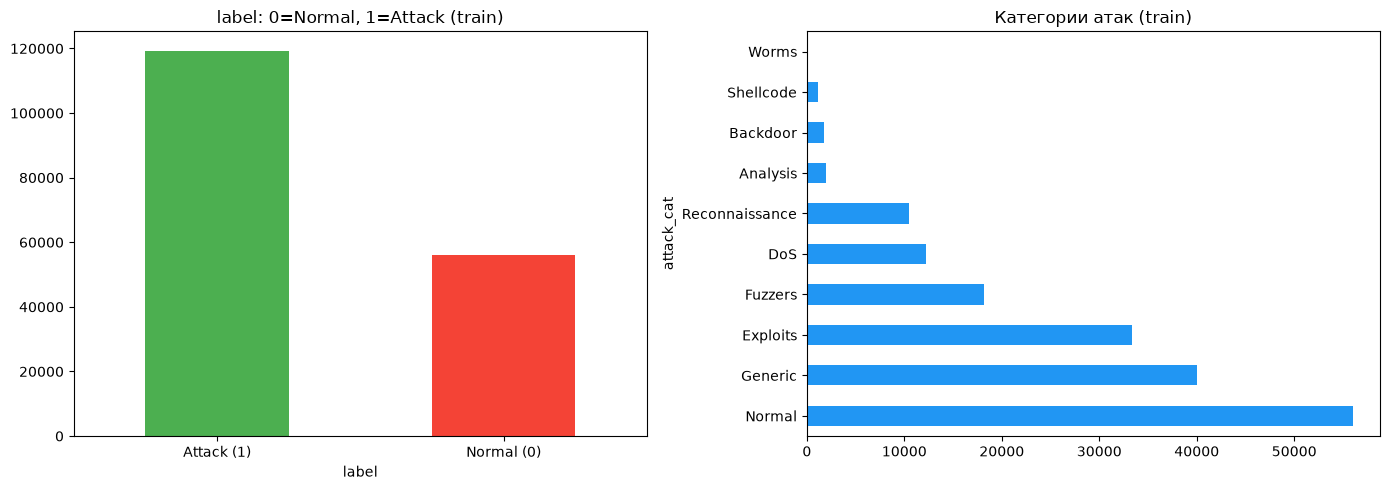

label
1    0.6806
0    0.3194
Name: proportion, dtype: float64


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

train["label"].value_counts().plot(kind="bar", ax=axes[0],
    color=["#4CAF50", "#F44336"])
axes[0].set_title("label: 0=Normal, 1=Attack (train)")
axes[0].set_xticklabels(["Attack (1)", "Normal (0)"], rotation=0)

train["attack_cat"].value_counts().plot(kind="barh", ax=axes[1], color="#2196F3")
axes[1].set_title("Категории атак (train)")

plt.tight_layout()
plt.savefig("../reports/eda_01_class_distribution.png", dpi=150)
plt.show()

print(train["label"].value_counts(normalize=True).round(4))

In [15]:
pd.set_option("display.float_format", lambda x: f"{x:.3g}")
train.describe().T[["mean", "std", "50%", "max"]]

,mean,std,50%,max
id,8.77e+04,5.06e+04,8.77e+04,1.75e+05
dur,1.36,6.48,0.00158,60
spkts,20.3,137,2,9.62e+03
dpkts,19,110,2,1.1e+04
sbytes,8.84e+03,1.75e+05,430,1.3e+07
dbytes,1.49e+04,1.44e+05,164,1.47e+07
rate,9.54e+04,1.65e+05,3.23e+03,1e+06
sttl,180,103,254,255
dttl,79.6,111,29,254
sload,7.35e+07,1.88e+08,8.8e+05,5.99e+09


In [16]:
cat_cols = train.select_dtypes(include="object").columns.tolist()
for col in cat_cols:
    print(f"\n=== {col} (уникальных: {train[col].nunique()}) ===")
    print(train[col].value_counts().head(6))


=== proto (уникальных: 133) ===
proto
tcp     79946
udp     63283
unas    12084
arp      2859
ospf     2595
sctp     1150
Name: count, dtype: int64

=== service (уникальных: 13) ===
service
-           94168
dns         47294
http        18724
smtp         5058
ftp-data     3995
ftp          3428
Name: count, dtype: int64

=== state (уникальных: 9) ===
state
INT    82275
FIN    77825
CON    13152
REQ     1991
RST       83
ECO       12
Name: count, dtype: int64

=== attack_cat (уникальных: 10) ===
attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Name: count, dtype: int64


C:\Users\User\AppData\Local\Temp\ipykernel_18072\2773161872.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = train.select_dtypes(include="object").columns.tolist()


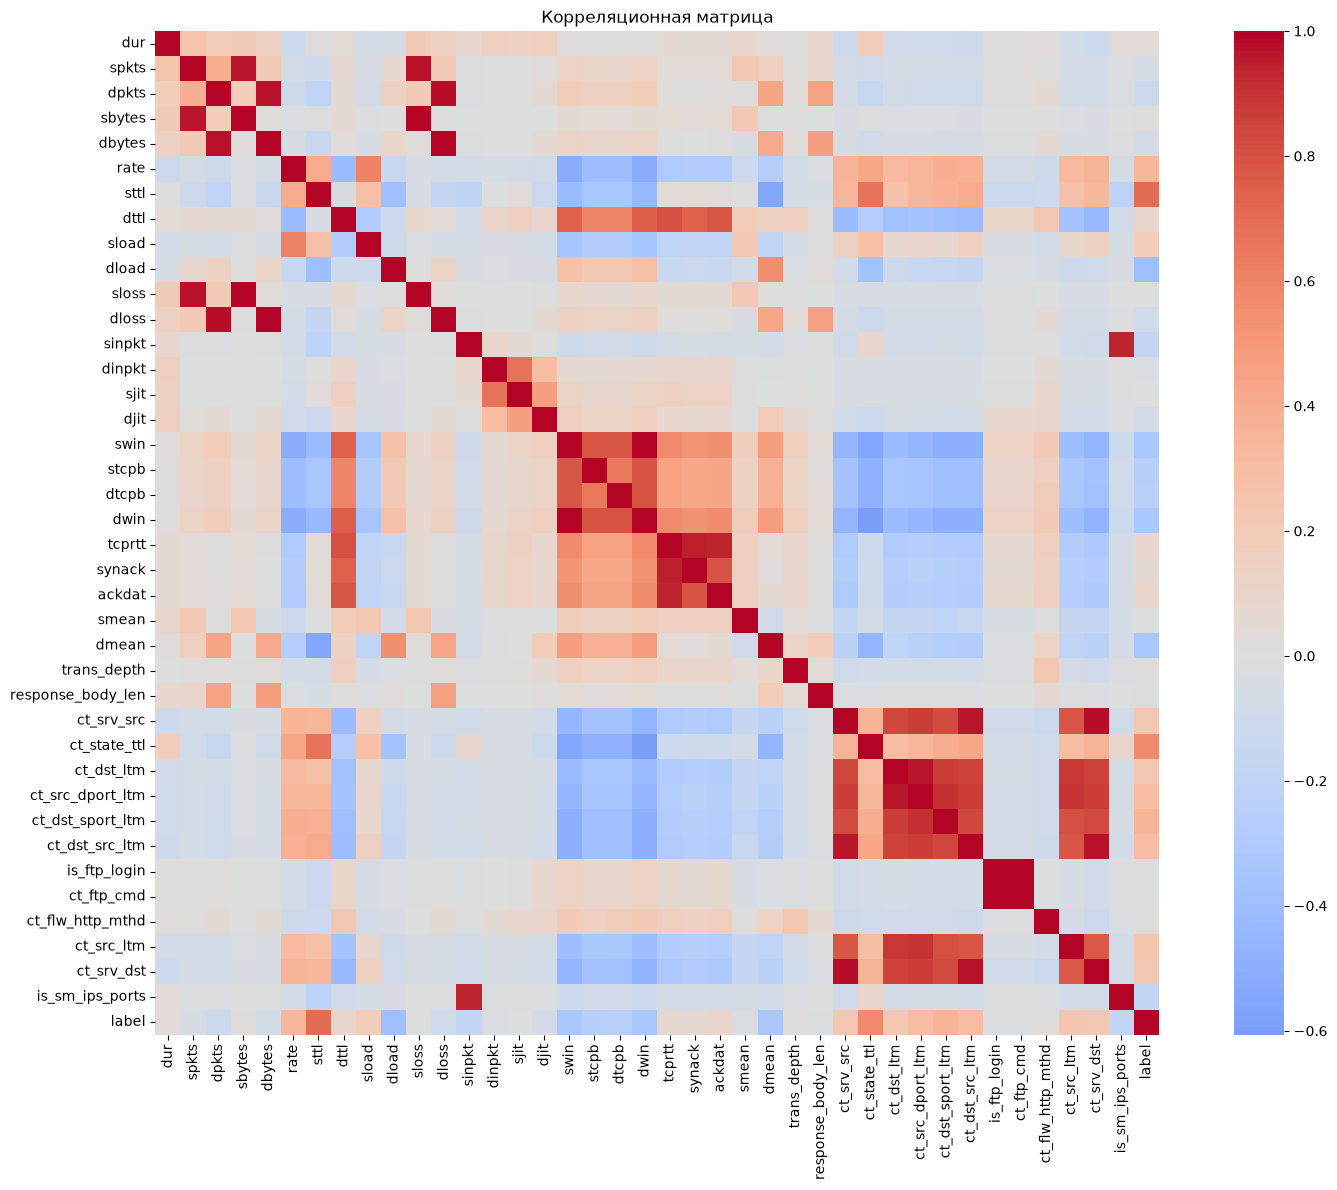

Топ-5 признаков по корреляции с label:
ct_src_dport_ltm   0.306
rate               0.338
ct_dst_sport_ltm   0.357
ct_state_ttl       0.578
sttl               0.693
Name: label, dtype: float64


In [17]:
num_cols = train.select_dtypes(include=[np.number]).columns.drop(["id", "label"])

corr = train[num_cols.tolist() + ["label"]].corr()

plt.figure(figsize=(16, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True)
plt.title("Корреляционная матрица")
plt.tight_layout()
plt.savefig("../reports/eda_02_heatmap.png", dpi=150)
plt.show()

print("Топ-5 признаков по корреляции с label:")
print(corr["label"].drop("label").sort_values().tail(5))

In [18]:
key_feats = ["rate", "sload", "sttl", "ct_dst_src_ltm", "sbytes",
             "ct_srv_src", "dur", "response_body_len", "dbytes"]

means = train.groupby("label")[key_feats].mean().T
means.columns = ["Normal", "Attack"]
means["Attack/Normal"] = (means["Attack"] / (means["Normal"] + 1e-9)).round(2)
print(means.sort_values("Attack/Normal", ascending=False))

                    Normal   Attack  Attack/Normal
rate              1.38e+04 1.34e+05           9.69
sload             2.32e+07  9.7e+07           4.19
sttl                  75.4      228           3.03
ct_dst_src_ltm        3.87       11           2.85
sbytes            4.11e+03 1.11e+04            2.7
ct_srv_src            5.73       11           1.92
dur                   1.02     1.52           1.49
response_body_len 3.83e+03 1.35e+03           0.35
dbytes             3.1e+04 7.36e+03           0.24
